# Ex. No: 07 
## Lane Detection using Hough Transform.

**Name :** E ARYA KRISHNA  **Reg. No :** 212225240014 **Slot No :** 26OD2199

In [3]:
# Import 
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# Read the image using OpenCV

image_path = "image.jpg"

img = cv2.imread(image_path)

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

In [6]:
# Convert to grayscale.

gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

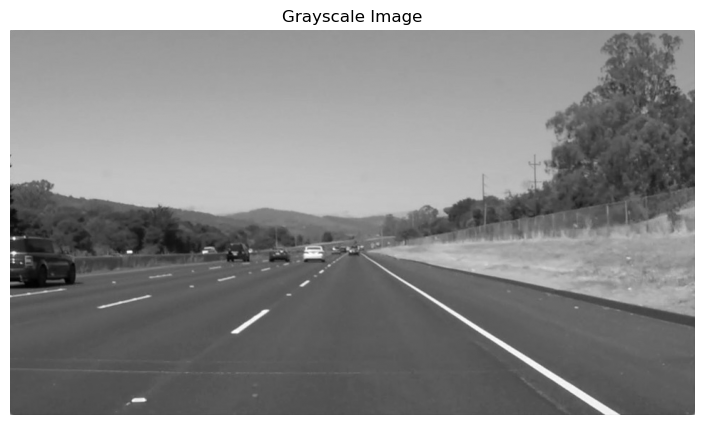

In [7]:
# Display the image using Matplotlib
plt.figure(figsize=(10,5))
plt.imshow(gray, cmap='gray')
plt.title("Grayscale Image")
plt.axis('off')
plt.show()

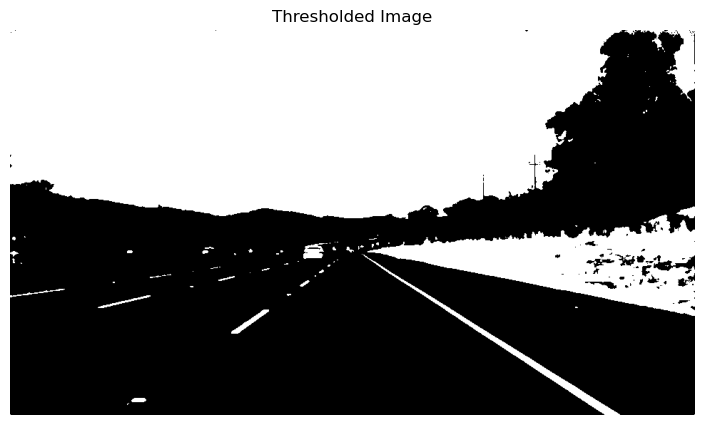

In [14]:
# Use global threshold based on grayscale intensity.


threshold = 150

_, thresh = cv2.threshold(gray, threshold, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(10,5))
plt.imshow(thresh, cmap='gray')
plt.title("Thresholded Image")
plt.axis('off')
plt.show()

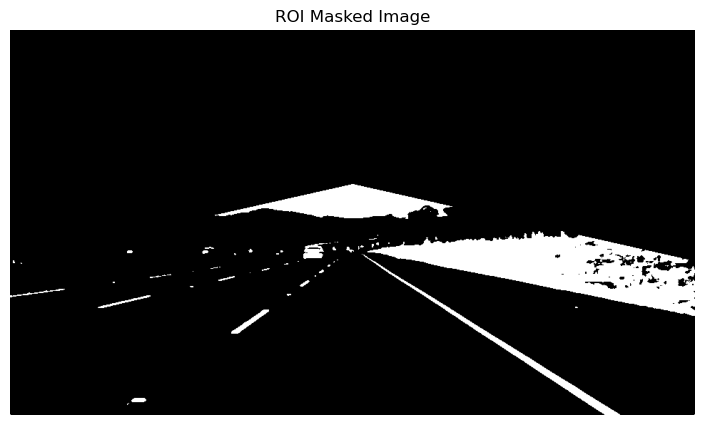

In [9]:
#  Region of Interest (ROI)
height, width = gray.shape

mask = np.zeros_like(gray)

polygon = np.array([[
    (0, height),
    (width, height),
    (width, int(height * 0.6)),
    (int(width * 0.5), int(height * 0.4)),
    (0, int(height * 0.6))
]], np.int32)

cv2.fillPoly(mask, polygon, 255)

roi = cv2.bitwise_and(thresh, mask)

plt.figure(figsize=(10,5))
plt.imshow(roi, cmap='gray')
plt.title("ROI Masked Image")
plt.axis('off')
plt.show()

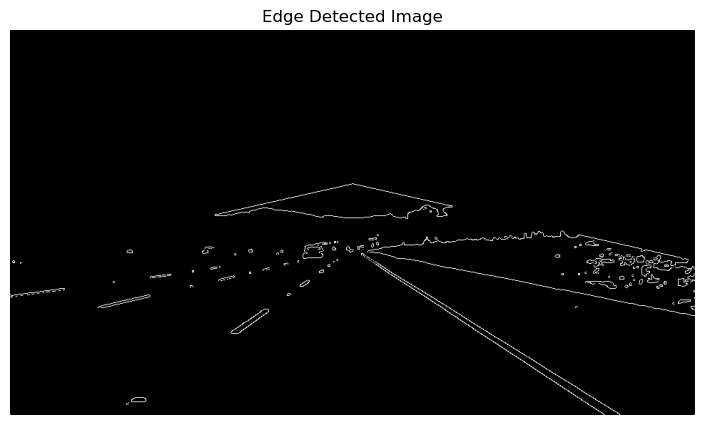

In [10]:
# Perform Edge Detection (using Cany)
edges = cv2.Canny(roi, 50, 150)

plt.figure(figsize=(10,5))
plt.imshow(edges, cmap='gray')
plt.title("Edge Detected Image")
plt.axis('off')
plt.show()

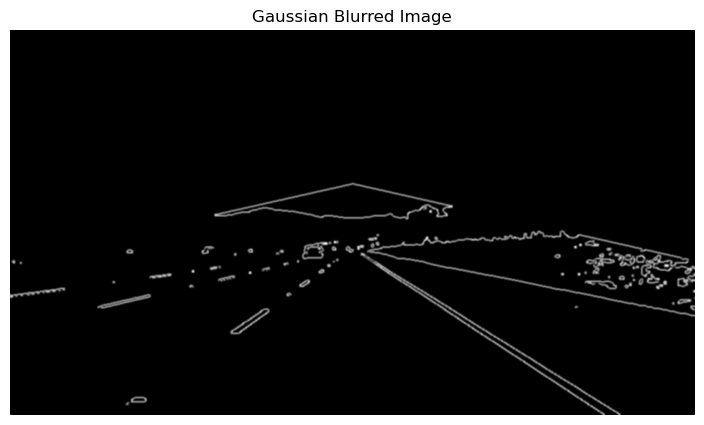

In [11]:
# Smooth with a Gaussian blur.
blur = cv2.GaussianBlur(edges, (5,5), 0)

plt.figure(figsize=(10,5))
plt.imshow(blur, cmap='gray')
plt.title("Gaussian Blurred Image")
plt.axis('off')
plt.show()

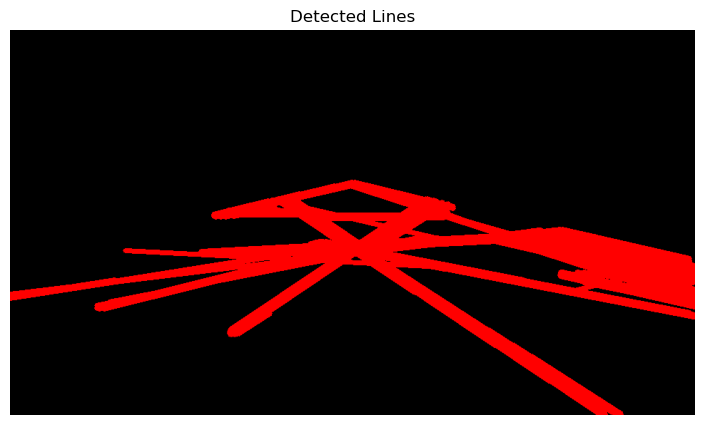

In [12]:

# Detect lines using Hough Transform

lines = cv2.HoughLinesP(
    blur,
    rho=1,
    theta=np.pi/180,
    threshold=50,
    minLineLength=40,
    maxLineGap=100
)

line_img = np.zeros_like(img)

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = np.array(line).flatten()[:4]

        cv2.line(line_img, (int(x1), int(y1)),
                 (int(x2), int(y2)), (255, 0, 0), 5)

plt.figure(figsize=(10,5))
plt.imshow(line_img)
plt.title("Detected Lines")
plt.axis('off')
plt.show()


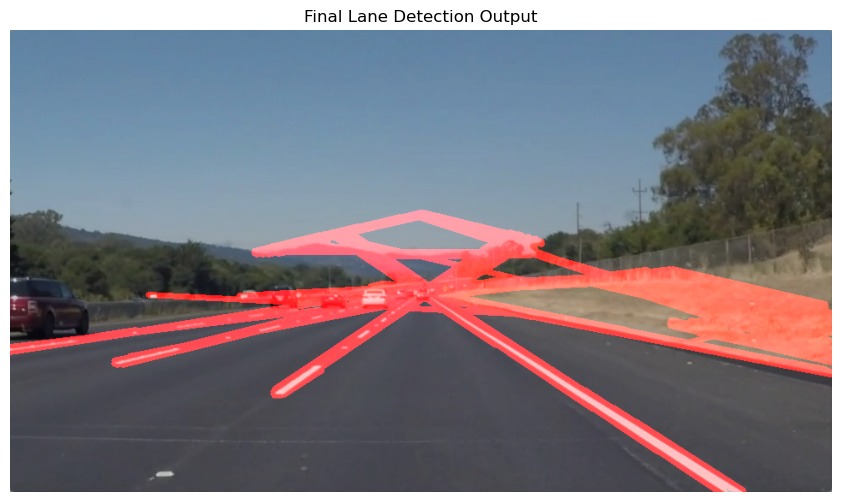

In [13]:
# Lane Detection Logic

final = cv2.addWeighted(img, 0.8, line_img, 1, 0)

plt.figure(figsize=(12,6))
plt.imshow(final)
plt.title("Final Lane Detection Output")
plt.axis('off')
plt.show()